In [ ]:

import numpy as np
import networkx as nx
from numpy.typing import NDArray
from scipy.special import betaln, gammaln, logsumexp
FloatArray = NDArray[np.float64]
IntArray = NDArray[np.int64]

## Simulation

### Network with 6 nodes

In [33]:
Y6 = np.array([
    [0, 1, 1, 0, 0, 0],
    [1, 0, 1, 0, 0, 0],
    [1, 1, 0, 1, 0, 0],
    [0, 0, 1, 0, 1, 1],
    [0, 0, 0, 1, 0, 0],
    [0, 0, 0, 1, 0, 0],
    ], dtype=int)

a = 1.0
b = 1.0
alpha = 1.5
assert Y6.shape == (6, 6)
assert np.array_equal(Y6, Y6.T)
assert np.all(np.diag(Y6) == 0)
assert np.all(np.isin(Y6, [0, 1]))
print("Number of nodes:", len(Y6))
print("Number of edges:", int(np.triu(Y6, k=1).sum()))


def enumerate_partitions(n):
    """Enumerates all partitions of n elements."""
    if n < 1:
        raise ValueError("n must be positive.")
    partitions = []
    def recurse(z, max_label):
        i = len(z)
        if i == n:
            partitions.append(tuple(z))
            return
        for label in range(max_label + 2):
            recurse(z + [label], max(max_label, label))
    recurse([0], 0)
    return partitions


partitions = enumerate_partitions(6)

print("Partitions enumerated:", len(partitions))


def log_marginal_sbm(Y, z, a=1.0, b=1.0):
    """Log-likelihood marginal of a binary undirected SBM."""
    Y = np.asarray(Y)
    z = np.asarray(z)
    n = len(z)
    if Y.shape != (n, n):
        raise ValueError("Incompatible dimensions between Y and z.")
    if not np.array_equal(Y, Y.T):
        raise ValueError("Y must be symmetric.")
    if np.any(np.diag(Y) != 0):
        raise ValueError("Y must have a zero diagonal.")
    if not np.all(np.isin(Y, [0, 1])):
        raise ValueError("Y must be binary.")
    if a <= 0 or b <= 0:
        raise ValueError("a and b must be positive.")
    labels = sorted(set(z))
    total = 0.0

    for pos, h in enumerate(labels):
        for k in labels[pos:]:
            nodes_h = np.flatnonzero(z == h)
            nodes_k = np.flatnonzero(z == k)
            if h == k:
                possible = len(nodes_h) * (len(nodes_h) - 1) // 2
                subgraph = Y[np.ix_(nodes_h, nodes_h)]
                edges = int(np.triu(subgraph, k=1).sum())
            else:
                possible = len(nodes_h) * len(nodes_k)
                edges = int(Y[np.ix_(nodes_h, nodes_k)].sum())

            non_edges = possible - edges

            total += betaln(a + edges, b + non_edges) - betaln(a, b)
    return float(total)

def log_prior_dp(z, alpha=1.5):
    z = np.asarray(z)
    n = len(z)
    sizes = np.unique(z, return_counts=True)[1]
    K = len(sizes)
    return gammaln(alpha) - gammaln(alpha + n) + K * np.log(alpha) + np.sum(gammaln(sizes)) 


log_priors = np.array([log_prior_dp(z, alpha) for z in partitions])
prior_probabilities = np.exp(log_priors)
print("Sum of prior probabilities:", prior_probabilities.sum())
assert np.isclose(prior_probabilities.sum(), 1.0)
log_likelihoods = np.array([log_marginal_sbm(Y6, z, a, b) for z in partitions])
log_joint = log_likelihoods + log_priors
log_evidence = logsumexp(log_joint)
exact_probabilities = np.exp(log_joint - log_evidence)
print("Sum of posterior probabilities:", exact_probabilities.sum())
assert np.isclose(exact_probabilities.sum(), 1.0)
order = np.argsort(exact_probabilities)[::-1]

print("\n Fifteen partitions with highest posterior probability:")
for idx in order[:15]:
    print(f"z={partitions[idx]}, "
        f"K={len(set(partitions[idx]))}, "
        f"p(z|Y)={exact_probabilities[idx]:.6f}" )


model4 = SBMModel(adjacency=Y6, a=a, b=b)
prior4 = PartitionPrior(kind="DP", alpha=alpha)
config4 = SamplerConfig(n_iterations=55_000, burn_in=5_000,thin=1)
sampler4 = GibbsSampler(model=model4,prior=prior4,config=config4)
result4 = sampler4.fit(initial_partition=np.array([0, 0, 1, 1, 1, 1]), seed=123)
def canonical_partition(z):
    mapping = {}
    result = []
    for label in z:
        if label not in mapping:
            mapping[label] = len(mapping)
        result.append(mapping[label])
    return tuple(result)
samples = result4["samples"]
if isinstance(samples, np.ndarray) and samples.ndim == 2:
    samples = [canonical_partition(z) for z in samples]
else:
    samples = [canonical_partition(z) for z in samples]
exact_map = {z: p for z, p in zip(partitions, exact_probabilities)}
counts = {z: 0 for z in partitions}
for z in samples:
    counts[z] += 1
empirical = np.array([counts[z] / len(samples) for z in partitions])
exact = np.array([exact_map[z] for z in partitions])
tv_distance = 0.5 * np.sum(np.abs(empirical - exact))
print("Number of samples:", len(samples))
print("Total variation distance:", tv_distance)
print("\nComparison of probabilities:")
for idx in order:
    print(f"{partitions[idx]} | "
        f"exact={exact[idx]:.4f} | "
        f"Gibbs={empirical[idx]:.4f}")

split_merge = SplitMergeSampler(model=model4, prior=prior4, config=config4)
result_sm = split_merge.fit(initial_partition=np.array([0, 0, 1, 1, 1, 1]), seed=123)
samples = result_sm["samples"]
if isinstance(samples, np.ndarray) and samples.ndim == 2:
    samples = [canonical_partition(z) for z in samples]
else:
    samples = [canonical_partition(z) for z in samples]
exact_map = {z: p for z, p in zip(partitions, exact_probabilities)}
counts = {z: 0 for z in partitions}
for z in samples:
    counts[z] += 1
empirical = np.array([counts[z] / len(samples) for z in partitions])
exact = np.array([exact_map[z] for z in partitions])
tv_distance = 0.5 * np.sum(np.abs(empirical - exact))
print("Number of samples:", len(samples))
print("Total variation distance:", tv_distance)
print("\nComparison of probabilities:")
for idx in order:
    print(f"{partitions[idx]} | "
        f"exact={exact[idx]:.4f} | "
        f"split-merge={empirical[idx]:.4f}")

chaperones = ChaperonesSampler(model=model4, prior=prior4, config=config4)
result_ch = chaperones.fit(initial_partition=np.array([0, 0, 1, 1, 1, 1]), seed=123)
samples = result_ch["samples"]
if isinstance(samples, np.ndarray) and samples.ndim == 2:
    samples = [canonical_partition(z) for z in samples]
else:
    samples = [canonical_partition(z) for z in samples]
exact_map = {z: p for z, p in zip(partitions, exact_probabilities)}
counts = {z: 0 for z in partitions}
for z in samples:
    counts[z] += 1
empirical = np.array([counts[z] / len(samples) for z in partitions])
exact = np.array([exact_map[z] for z in partitions])
tv_distance = 0.5 * np.sum(np.abs(empirical - exact))
print("Number of samples:", len(samples))
print("Total variation distance:", tv_distance)
print("\nComparison of probabilities:")
for idx in order:
    print(f"{partitions[idx]} | "
        f"exact={exact[idx]:.4f} | "
        f"chaperones={empirical[idx]:.4f}")

Number of nodes: 6
Number of edges: 6
Partitions enumerated: 203
Sum of prior probabilities: 0.9999999999999998
Sum of posterior probabilities: 0.9999999999999997

 Fifteen partitions with highest posterior probability:
z=(0, 0, 0, 1, 2, 2), K=3, p(z|Y)=0.076930
z=(0, 0, 0, 0, 0, 0), K=1, p(z|Y)=0.051646
z=(0, 0, 0, 1, 1, 1), K=2, p(z|Y)=0.047868
z=(0, 0, 0, 1, 2, 3), K=4, p(z|Y)=0.037864
z=(0, 0, 1, 2, 3, 3), K=4, p(z|Y)=0.035901
z=(0, 0, 1, 2, 2, 2), K=3, p(z|Y)=0.025643
z=(0, 0, 0, 1, 2, 1), K=3, p(z|Y)=0.019233
z=(0, 0, 0, 1, 1, 2), K=3, p(z|Y)=0.019233
z=(0, 1, 1, 2, 3, 3), K=4, p(z|Y)=0.017950
z=(0, 1, 0, 2, 3, 3), K=4, p(z|Y)=0.017950
z=(0, 1, 2, 3, 4, 4), K=5, p(z|Y)=0.016829
z=(0, 0, 1, 2, 3, 4), K=5, p(z|Y)=0.016829
z=(0, 0, 1, 0, 0, 0), K=2, p(z|Y)=0.015666
z=(0, 0, 0, 1, 0, 0), K=2, p(z|Y)=0.015666
z=(0, 0, 1, 2, 1, 1), K=3, p(z|Y)=0.015386


Sampling: 100%|██████████| 55000/55000 [09:20<00:00, 98.19it/s] 


Number of samples: 50000
Total variation distance: 0.018789869916078908

Comparison of probabilities:
(0, 0, 0, 1, 2, 2) | exact=0.0769 | Gibbs=0.0762
(0, 0, 0, 0, 0, 0) | exact=0.0516 | Gibbs=0.0528
(0, 0, 0, 1, 1, 1) | exact=0.0479 | Gibbs=0.0477
(0, 0, 0, 1, 2, 3) | exact=0.0379 | Gibbs=0.0370
(0, 0, 1, 2, 3, 3) | exact=0.0359 | Gibbs=0.0365
(0, 0, 1, 2, 2, 2) | exact=0.0256 | Gibbs=0.0265
(0, 0, 0, 1, 2, 1) | exact=0.0192 | Gibbs=0.0190
(0, 0, 0, 1, 1, 2) | exact=0.0192 | Gibbs=0.0196
(0, 1, 1, 2, 3, 3) | exact=0.0180 | Gibbs=0.0178
(0, 1, 0, 2, 3, 3) | exact=0.0180 | Gibbs=0.0180
(0, 1, 2, 3, 4, 4) | exact=0.0168 | Gibbs=0.0177
(0, 0, 1, 2, 3, 4) | exact=0.0168 | Gibbs=0.0163
(0, 0, 1, 0, 0, 0) | exact=0.0157 | Gibbs=0.0158
(0, 0, 0, 1, 0, 0) | exact=0.0157 | Gibbs=0.0165
(0, 0, 1, 2, 1, 1) | exact=0.0154 | Gibbs=0.0153
(0, 0, 0, 0, 1, 0) | exact=0.0149 | Gibbs=0.0150
(0, 0, 0, 0, 0, 1) | exact=0.0149 | Gibbs=0.0150
(0, 1, 1, 2, 2, 2) | exact=0.0128 | Gibbs=0.0130
(0, 1, 0, 2, 2, 

Sampling: 100%|██████████| 55000/55000 [00:36<00:00, 1512.87it/s]


Number of samples: 50000
Total variation distance: 0.03277976877706223

Comparison of probabilities:
(0, 0, 0, 1, 2, 2) | exact=0.0769 | split-merge=0.0756
(0, 0, 0, 0, 0, 0) | exact=0.0516 | split-merge=0.0515
(0, 0, 0, 1, 1, 1) | exact=0.0479 | split-merge=0.0484
(0, 0, 0, 1, 2, 3) | exact=0.0379 | split-merge=0.0389
(0, 0, 1, 2, 3, 3) | exact=0.0359 | split-merge=0.0385
(0, 0, 1, 2, 2, 2) | exact=0.0256 | split-merge=0.0246
(0, 0, 0, 1, 2, 1) | exact=0.0192 | split-merge=0.0202
(0, 0, 0, 1, 1, 2) | exact=0.0192 | split-merge=0.0176
(0, 1, 1, 2, 3, 3) | exact=0.0180 | split-merge=0.0174
(0, 1, 0, 2, 3, 3) | exact=0.0180 | split-merge=0.0171
(0, 1, 2, 3, 4, 4) | exact=0.0168 | split-merge=0.0164
(0, 0, 1, 2, 3, 4) | exact=0.0168 | split-merge=0.0174
(0, 0, 1, 0, 0, 0) | exact=0.0157 | split-merge=0.0165
(0, 0, 0, 1, 0, 0) | exact=0.0157 | split-merge=0.0153
(0, 0, 1, 2, 1, 1) | exact=0.0154 | split-merge=0.0145
(0, 0, 0, 0, 1, 0) | exact=0.0149 | split-merge=0.0132
(0, 0, 0, 0, 0, 1) 

Sampling: 100%|██████████| 55000/55000 [04:35<00:00, 199.59it/s]


Number of samples: 50000
Total variation distance: 0.032941225985071015

Comparison of probabilities:
(0, 0, 0, 1, 2, 2) | exact=0.0769 | chaperones=0.0794
(0, 0, 0, 0, 0, 0) | exact=0.0516 | chaperones=0.0545
(0, 0, 0, 1, 1, 1) | exact=0.0479 | chaperones=0.0473
(0, 0, 0, 1, 2, 3) | exact=0.0379 | chaperones=0.0364
(0, 0, 1, 2, 3, 3) | exact=0.0359 | chaperones=0.0314
(0, 0, 1, 2, 2, 2) | exact=0.0256 | chaperones=0.0251
(0, 0, 0, 1, 2, 1) | exact=0.0192 | chaperones=0.0195
(0, 0, 0, 1, 1, 2) | exact=0.0192 | chaperones=0.0204
(0, 1, 1, 2, 3, 3) | exact=0.0180 | chaperones=0.0178
(0, 1, 0, 2, 3, 3) | exact=0.0180 | chaperones=0.0168
(0, 1, 2, 3, 4, 4) | exact=0.0168 | chaperones=0.0153
(0, 0, 1, 2, 3, 4) | exact=0.0168 | chaperones=0.0156
(0, 0, 1, 0, 0, 0) | exact=0.0157 | chaperones=0.0172
(0, 0, 0, 1, 0, 0) | exact=0.0157 | chaperones=0.0160
(0, 0, 1, 2, 1, 1) | exact=0.0154 | chaperones=0.0151
(0, 0, 0, 0, 1, 0) | exact=0.0149 | chaperones=0.0163
(0, 0, 0, 0, 0, 1) | exact=0.0149 


===== Gibbs =====
Número de muestras: 50000
TV final: 0.018789869916078908
ESS de K: 28545.652847196478
ESS mínimo entre estados: 30162.180212186577
ESS mediano entre estados: 50000.0

===== Split-Merge =====
Número de muestras: 50000
TV final: 0.03277976877706223
ESS de K: 4765.660869075879
ESS mínimo entre estados: 4171.3489831094685
ESS mediano entre estados: 23947.380549491034

===== Chaperones =====
Número de muestras: 50000
TV final: 0.032941225985071015
ESS de K: 3978.3624434621383
ESS mínimo entre estados: 8267.197430375052
ESS mediano entre estados: 30380.98692073952


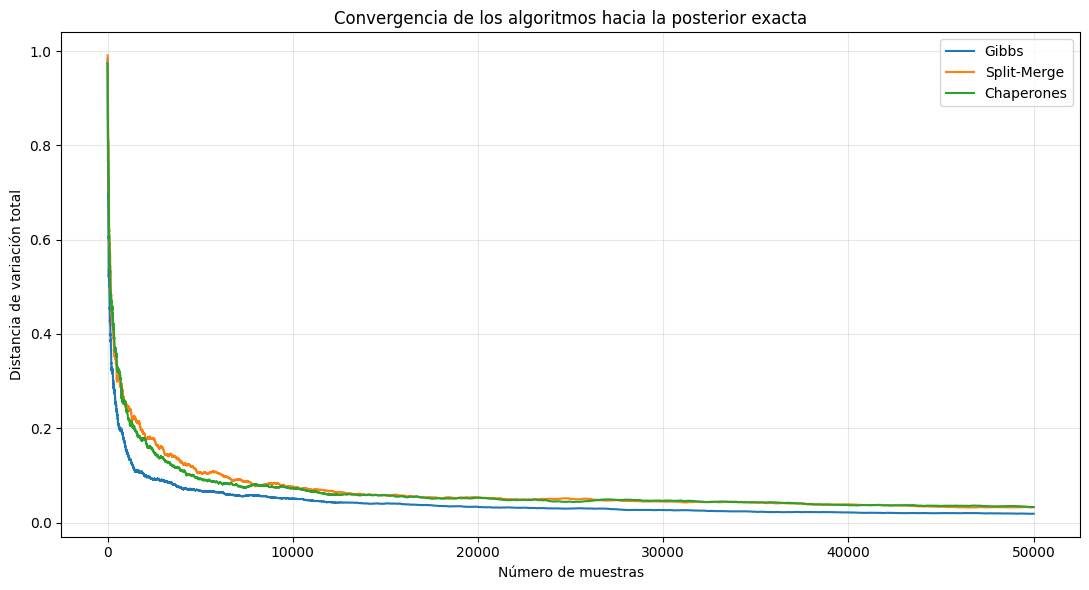

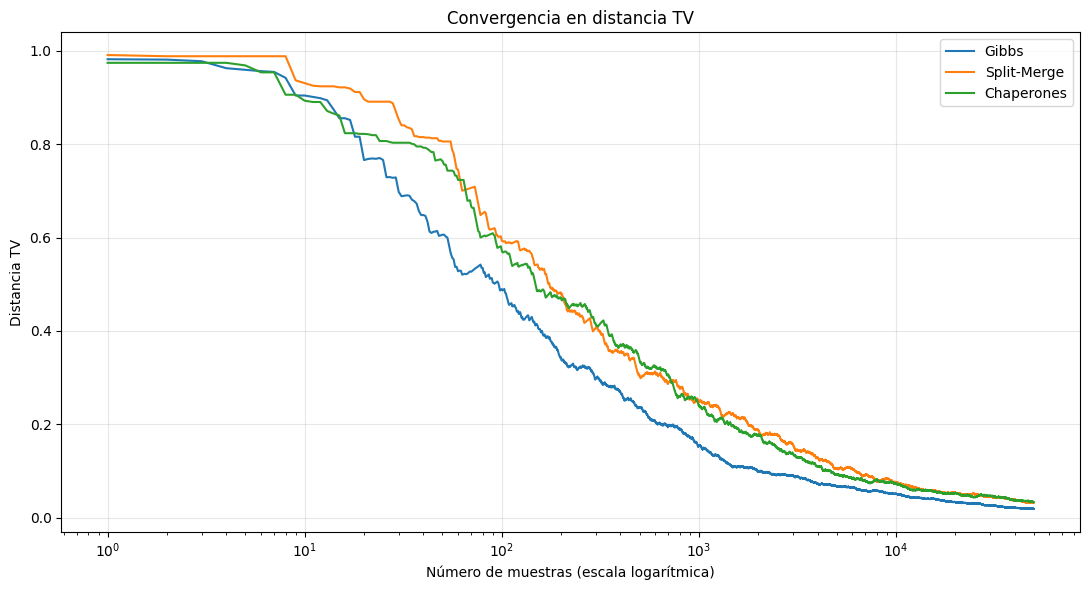

                 ESS de K    ESS mínimo   ESS mediano
Gibbs        28545.652847  30162.180212  50000.000000
Split-Merge   4765.660869   4171.348983  23947.380549
Chaperones    3978.362443   8267.197430  30380.986921


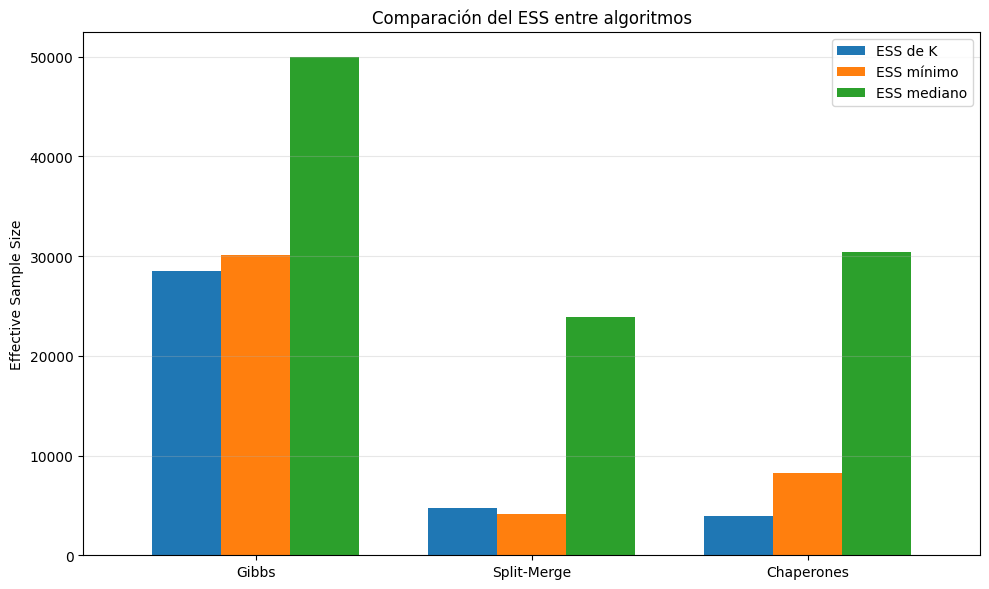

In [34]:
import numpy as np
import matplotlib.pyplot as plt


def tv_distance_trajectory(samples, partitions, exact_probabilities):
    """
    Calcula la distancia TV acumulada a lo largo de la cadena.
    """
    n_samples = len(samples)
    n_states = len(partitions)

    partition_index = {z: i for i, z in enumerate(partitions)}

    exact = np.asarray(exact_probabilities)

    # Representación de cada muestra mediante su índice de estado
    indices = np.array([partition_index[z] for z in samples])

    # Conteos acumulados de cada partición
    counts = np.zeros((n_samples, n_states), dtype=int)

    for t, idx in enumerate(indices):
        if t == 0:
            counts[t, idx] = 1
        else:
            counts[t] = counts[t - 1]
            counts[t, idx] += 1

    # Distribuciones empíricas acumuladas
    empirical = counts / np.arange(1, n_samples + 1)[:, None]

    # Distancia de variación total
    tv = 0.5 * np.sum(np.abs(empirical - exact), axis=1)

    return tv


def ess_1d(x):
    """
    ESS mediante la secuencia positiva inicial de Geyer.
    """
    x = np.asarray(x, dtype=float)
    n = len(x)

    if n < 4 or np.var(x) == 0:
        return np.nan

    x = x - np.mean(x)

    # Autocorrelación mediante FFT
    fft = np.fft.rfft(x, n=2*n)
    acov = np.fft.irfft(fft * np.conjugate(fft))[:n]

    acov /= np.arange(n, 0, -1)

    rho = acov / acov[0]

    # Sumas por pares de autocorrelaciones
    tau_sum = 0.0

    for k in range(1, n - 1, 2):
        pair_sum = rho[k] + rho[k + 1]

        if pair_sum <= 0:
            break

        tau_sum += pair_sum

    tau = max(1.0, 1.0 + 2.0 * tau_sum)

    return min(float(n), float(n / tau))


def calculate_ess(samples, partitions):
    """
    Calcula ESS para:
    1. Cada partición mediante variables indicadoras.
    2. El número de grupos K.
    """
    n = len(samples)

    partition_index = {z: i for i, z in enumerate(partitions)}
    indices = np.array([partition_index[z] for z in samples])

    # ESS para cada estado
    ess_states = np.array([
        ess_1d((indices == j).astype(float))
        for j in range(len(partitions))
    ])

    # ESS para el número de grupos
    K = np.array([len(set(z)) for z in samples])
    ess_K = ess_1d(K)

    valid = ess_states[np.isfinite(ess_states)]

    return {
        "ESS_states": ess_states,
        "ESS_K": ess_K,
        "ESS_min": np.min(valid) if len(valid) else np.nan,
        "ESS_median": np.median(valid) if len(valid) else np.nan,
        "K": K
    }


def evaluate_sampler(result, name, partitions, exact_probabilities):

    raw_samples = result["samples"]

    samples = [
        canonical_partition(z)
        for z in raw_samples
    ]

    tv = tv_distance_trajectory(
        samples,
        partitions,
        exact_probabilities
    )

    ess = calculate_ess(samples, partitions)

    print(f"\n===== {name} =====")
    print("Número de muestras:", len(samples))
    print("TV final:", tv[-1])
    print("ESS de K:", ess["ESS_K"])
    print("ESS mínimo entre estados:", ess["ESS_min"])
    print("ESS mediano entre estados:", ess["ESS_median"])

    return {
        "name": name,
        "samples": samples,
        "TV": tv,
        "ESS": ess
    }

results = {}

results["Gibbs"] = evaluate_sampler(
    result4,
    "Gibbs",
    partitions,
    exact_probabilities
)

results["Split-Merge"] = evaluate_sampler(
    result_sm,
    "Split-Merge",
    partitions,
    exact_probabilities
)

results["Chaperones"] = evaluate_sampler(
    result_ch,
    "Chaperones",
    partitions,
    exact_probabilities
)

plt.figure(figsize=(11, 6))

for name, res in results.items():
    plt.plot(
        np.arange(1, len(res["TV"]) + 1),
        res["TV"],
        label=name,
        linewidth=1.5
    )

plt.xlabel("Número de muestras")
plt.ylabel("Distancia de variación total")
plt.title("Convergencia de los algoritmos hacia la posterior exacta")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 6))

for name, res in results.items():
    plt.plot(
        np.arange(1, len(res["TV"]) + 1),
        res["TV"],
        label=name,
        linewidth=1.5
    )

plt.xscale("log")
plt.xlabel("Número de muestras (escala logarítmica)")
plt.ylabel("Distancia TV")
plt.title("Convergencia en distancia TV")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


import pandas as pd

ess_comparison = pd.DataFrame({
    name: {
        "ESS de K": res["ESS"]["ESS_K"],
        "ESS mínimo": res["ESS"]["ESS_min"],
        "ESS mediano": res["ESS"]["ESS_median"]
    }
    for name, res in results.items()
}).T

print(ess_comparison)


ess_comparison.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.ylabel("Effective Sample Size")
plt.title("Comparación del ESS entre algoritmos")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Network with 100 nodes

In [ ]:


def build_priors(n):
    priors = {
        "DM": PartitionPrior(
            kind="DM",
            beta=3.5 / 50,
            H_total=50
        ),

        "DP": PartitionPrior(
            kind="DP",
            alpha=3.0
        ),

        "PY": PartitionPrior(
            kind="PY",
            alpha=-0.3,
            sigma=0.6
        ),

        "GN": PartitionPrior(
            kind="GN",
            gamma=0.45
        )
    }
    from scipy.stats import poisson
    mfm_lambda = 5.0
    k_values = np.arange(1, n + 1)
    p_k = poisson.pmf(k_values, mfm_lambda)

    # Truncamiento a K <= n y normalización.
    p_k = p_k / p_k.sum()

    priors["MFM"] = PartitionPrior(
        kind="MFM",
        rho=1.0,
        p_k=tuple(p_k)
    )

    return priors



from sklearn.metrics import mutual_info_score
from scipy.stats import entropy

def variation_of_information(z1, z2):
    """
    VI(z1, z2) = H(z1) + H(z2) - 2 I(z1, z2).

    Las etiquetas pueden estar renombradas arbitrariamente.
    """
    z1 = np.asarray(z1)
    z2 = np.asarray(z2)

    h1 = entropy(np.unique(z1, return_counts=True)[1])
    h2 = entropy(np.unique(z2, return_counts=True)[1])

    mutual_information = mutual_info_score(z1, z2)

    return float(h1 + h2 - 2 * mutual_information)



def posterior_vi_summary(samples, z_true=None):
    """
    Resumen de VI y número de comunidades.
    """
    samples = [np.asarray(z) for z in samples]

    n_samples = len(samples)

    if n_samples == 0:
        raise ValueError("No hay muestras posteriores.")

    K_samples = np.array([
        len(np.unique(z)) for z in samples
    ])

    # Matriz de distancias VI.
    D = np.zeros((n_samples, n_samples))

    for i in range(n_samples):
        for j in range(i + 1, n_samples):
            d = variation_of_information(samples[i], samples[j])
            D[i, j] = d
            D[j, i] = d

    # Medoid posterior.
    medoid_index = np.argmin(D.mean(axis=1))
    z_hat = samples[medoid_index]

    # VI posterior media respecto a z0.
    if z_true is not None:
        vi_true = np.mean([
            variation_of_information(z, z_true)
            for z in samples
        ])
        vi_hat_true = variation_of_information(z_hat, z_true)
    else:
        vi_true = np.nan
        vi_hat_true = np.nan

    # Radio posterior aproximado:
    # percentil 95% de la distancia al medoid.
    distances_to_medoid = D[medoid_index, :]
    vi_radius = np.quantile(distances_to_medoid, 0.95)

    return {
        "K_mean": K_samples.mean(),
        "K_median": np.median(K_samples),
        "K_IQR": (
            np.quantile(K_samples, 0.25),
            np.quantile(K_samples, 0.75)
        ),
        "VI_mean_true": vi_true,
        "VI_hat_true": vi_hat_true,
        "VI_radius": vi_radius,
        "z_hat": z_hat
    }

from scipy.special import logsumexp
from scipy.stats import beta as beta_dist

def calculate_waic(model, samples, rng=None):
    """
    WAIC punto a punto para SBM binario no dirigido.

    Integra z mediante muestras posteriores y simula theta
    desde su posterior Beta condicionada a cada partición.
    """
    rng = np.random.default_rng(rng)

    Y = model.adjacency
    n = model.n_nodes

    rows, cols = np.triu_indices(n, k=1)
    y_obs = Y[rows, cols]

    S = len(samples)
    log_lik = np.zeros((S, len(rows)))

    for s, z in enumerate(samples):
        stats = model.block_statistics(z)

        z = stats["labels"]
        edges = stats["edges"]
        non_edges = stats["non_edges"]

        K = len(stats["sizes"])

        # Muestreo posterior de theta_hk.
        theta = np.zeros((K, K))

        for h in range(K):
            for k in range(h, K):
                theta_hk = rng.beta(
                    model.a + edges[h, k],
                    model.b + non_edges[h, k]
                )

                theta[h, k] = theta_hk
                theta[k, h] = theta_hk

        p = theta[z[rows], z[cols]]
        p = np.clip(p, 1e-12, 1 - 1e-12)

        log_lik[s, :] = (
            y_obs * np.log(p)
            + (1 - y_obs) * np.log(1 - p)
        )

    lppd = np.sum(
        logsumexp(log_lik, axis=0) - np.log(S)
    )

    p_waic = np.sum(
        np.var(log_lik, axis=0, ddof=1)
    )

    waic = -2 * (lppd - p_waic)

    return float(waic)


import time
import pandas as pd

def get_sampler(algorithm, model, prior, config):
    """
    Instancia el algoritmo usando las clases ya construidas.
    """
    if algorithm == "Gibbs":
        return GibbsSampler(model=model, prior=prior, config=config)

    if algorithm == "Split-Merge":
        return SplitMergeSampler(
            model=model, prior=prior, config=config
        )

    if algorithm == "Chaperones":
        return ChaperonesSampler(
            model=model, prior=prior, config=config
        )

    raise ValueError(f"Algoritmo desconocido: {algorithm}")


def run_algorithm(
    Y,
    prior,
    algorithm,
    z_true=None,
    n_iterations=15000,
    burn_in=5000,
    thin=10,
    seed=123
):
    """
    Ejecuta un algoritmo de inferencia para una red Y.

    Devuelve métricas posteriores y tiempos.
    """
    model = SBMModel(adjacency=Y, a=1.0, b=1.0)

    config = SamplerConfig(
        n_iterations=n_iterations,
        burn_in=burn_in,
        thin=thin
    )

    # Inicialización: un nodo por comunidad.
    z_initial = np.zeros(model.n_nodes, dtype=int)

    sampler = get_sampler(
        algorithm=algorithm,
        model=model,
        prior=prior,
        config=config
    )

    start = time.perf_counter()

    result = sampler.fit(
        initial_partition=z_initial,
        seed=seed
    )

    elapsed = time.perf_counter() - start

    samples = [
        np.asarray(z)
        for z in result["samples"]
    ]

    summary = posterior_vi_summary(
        samples,
        z_true=z_true
    )

    waic = calculate_waic(
        model=model,
        samples=samples,
        rng=seed
    )

    return {
        "algorithm": algorithm,
        "prior": prior.kind,
        "WAIC": waic,
        "VI_mean_true": summary["VI_mean_true"],
        "VI_hat_true": summary["VI_hat_true"],
        "K_mean": summary["K_mean"],
        "K_median": summary["K_median"],
        "K_IQR": summary["K_IQR"],
        "VI_radius": summary["VI_radius"],
        "time_seconds": elapsed,
        "n_samples": len(samples),
        "samples": samples,
        "log_posterior": result["log_posterior"],
        "n_communities_trace": result["n_communities"]
    }

def benchmark_algorithms(
    scenarios,
    priors,
    algorithms=("Gibbs", "Split-Merge", "Chaperones"),
    n_iterations=15000,
    burn_in=5000,
    thin=10,
    seed=123
):
    """
    Ejecuta todos los algoritmos sobre todos los escenarios
    y priors.

    scenarios:
        {
            "Scenario 1": {"Y": Y1, "z0": z01},
            "Scenario 2": {"Y": Y2, "z0": z02},
            ...
        }

    Devuelve:
        results: resultados completos
        tables: una tabla por algoritmo
    """

    results = []

    for scenario_name, scenario in scenarios.items():

        Y = np.asarray(scenario["Y"])
        z0 = scenario.get("z0", None)

        for algorithm in algorithms:

            for prior_name, prior in priors.items():

                print(
                    f"{scenario_name} | "
                    f"{algorithm} | {prior_name}"
                )

                output = run_algorithm(
                    Y=Y,
                    prior=prior,
                    algorithm=algorithm,
                    z_true=z0,
                    n_iterations=n_iterations,
                    burn_in=burn_in,
                    thin=thin,
                    seed=seed
                )

                output["scenario"] = scenario_name
                output["prior"] = prior_name

                results.append(output)

    results_df = pd.DataFrame(results)

    tables = {
        algorithm: results_df[
            results_df["algorithm"] == algorithm
        ].copy()
        for algorithm in algorithms
    }

    return results_df, tables


In [ ]:

# Los escenarios deben tener las matrices Y y sus particiones verdaderas z0.
scenarios = {
    "Scenario 1": {"Y": Y1, "z0": z1},
    "Scenario 2": {"Y": Y2, "z0": z2},
    "Scenario 3": {"Y": Y3, "z0": z3}
}

priors = build_priors(n=Y1.shape[0])

results_df, tables = benchmark_algorithms(
    scenarios=scenarios,
    priors=priors,
    n_iterations=150,
    burn_in=50,
    thin=1,
    seed=123
)

table_gibbs = tables["Gibbs"]
table_split_merge = tables["Split-Merge"]
table_chaperones = tables["Chaperones"]

display(table_gibbs)
display(table_split_merge)
display(table_chaperones)


## Applications

### Zachary Karate Club

In [ ]:
# Zachary Karate Club network
G = nx.karate_club_graph()
Y = nx.to_numpy_array(G, dtype=np.int64)
Y = (Y>1).astype(int)
labels = [G.nodes[i]["club"] for i in G.nodes()]
_, z_true = np.unique(labels, return_inverse=True)
z_true = z_true.astype(np.int64)
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Number of real communities:", len(np.unique(z_true)))
print("Size of the matrix:", Y.shape)



Number of nodes: 34
Number of edges: 78
Number of real communities: 2
Size of the matrix: (34, 34)


In [18]:
priors = {
    "DP": PartitionPrior(kind="DP", alpha=3.0),
    "PY": PartitionPrior(kind="PY", alpha=-0.3, sigma=0.6),
    "DM": PartitionPrior(kind="DM", beta=3.5/5, H_total=5),
    "MFM": PartitionPrior(kind="MFM",rho=1.0,p_k=(0.05, 0.10, 0.20, 0.30, 0.35)),
    "GN": PartitionPrior(kind="GN", gamma=0.45),
}
results = []

for name, prior in priors.items():
    results.append({"prior": name,
        "log-probability of real partition": prior.log_probability(z_true),
        "real communities": len(np.unique(z_true)),
        "community sizes": str(np.bincount(z_true))})

comparison = pd.DataFrame(results)
comparison

,prior,log-probability of real partition,real communities,community sizes
0,DP,-31.485603,2,[17 17]
1,PY,-28.537216,2,[17 17]
2,DM,-28.548888,2,[17 17]
3,MFM,-26.377086,2,[17 17]
4,GN,-26.430417,2,[17 17]


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

a, b = 1.0, 1.0

n = Y.shape[0]
n_edges = int(np.triu(Y, k=1).sum())

assert Y.shape == (n, n)
assert np.array_equal(Y, Y.T)
assert np.all(np.diag(Y) == 0)
assert np.all(np.isin(Y, [0, 1]))

print(f"Nodes: {n}")
print(f"Edges: {n_edges}")
print(f"Density: {2*n_edges/(n*(n-1)):.4f}")
print(f"True communities: {len(np.unique(z_true))}")
print(f"True community sizes: {np.unique(z_true, return_counts=True)[1]}")

Nodes: 34
Edges: 72
Density: 0.1283
True communities: 2
True community sizes: [17 17]


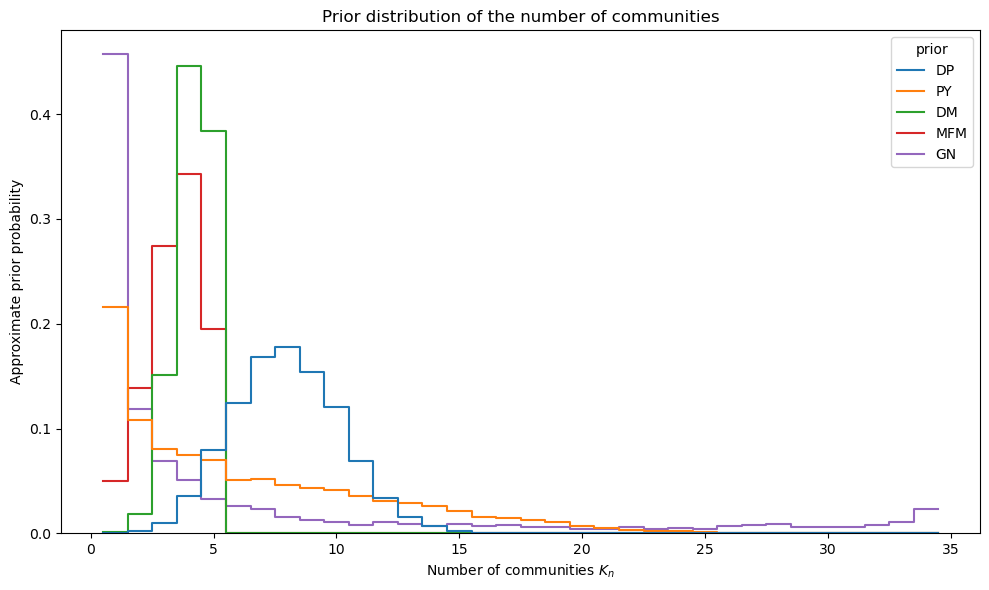

,prior,log_prior_true,K_true,sizes_true
0,DP,-31.485603,2,"[17, 17]"
1,PY,-28.537216,2,"[17, 17]"
2,DM,-28.548888,2,"[17, 17]"
3,MFM,-26.377086,2,"[17, 17]"
4,GN,-26.430417,2,"[17, 17]"


In [20]:
def simulate_partition(prior, n, rng):
    z = [0]
    sizes = [1]
    for i in range(1, n):
        probs = np.asarray(prior.predictive_probabilities(sizes),dtype=float)
        probs = probs / probs.sum()
        choice = rng.choice(len(probs), p=probs)
        if choice == len(sizes):
            sizes.append(1)
            z.append(len(sizes) - 1)
        else:
            sizes[choice] += 1
            z.append(choice)
    return np.asarray(z, dtype=int)

def simulate_prior_study(priors, n, n_sim=5000, seed=123):
    rng = np.random.default_rng(seed)
    records = []
    partitions = {}
    for name, prior in priors.items():
        samples = []
        for _ in range(n_sim):
            z = simulate_partition(prior, n, rng)
            samples.append(z)
            sizes = np.unique(z, return_counts=True)[1]
            records.append({
                "prior": name,
                "K": len(sizes),
                "largest_group": sizes.max(),
                "smallest_group": sizes.min(),
                "singleton_groups": np.sum(sizes == 1)})
        partitions[name] = samples
    return pd.DataFrame(records), partitions


prior_df, prior_samples = simulate_prior_study(priors, n=n, n_sim=5000, seed=123)
summary_prior = (prior_df.groupby("prior").agg(
        E_K=("K", "mean"),
        SD_K=("K", "std"),
        Median_K=("K", "median"),
        Q05=("K", lambda x: x.quantile(0.05)),
        Q95=("K", lambda x: x.quantile(0.95)),
        E_singletons=("singleton_groups", "mean"),
        E_largest_group=("largest_group", "mean")).round(3))
summary_prior

plt.figure(figsize=(10, 6))
sns.histplot(data=prior_df, x="K", hue="prior", stat="probability", common_norm=False, discrete=True, element="step", fill=False)
plt.xlabel(r"Number of communities $K_n$")
plt.ylabel("Approximate prior probability")
plt.title("Prior distribution of the number of communities")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame([{
        "prior": name, "log_prior_true": prior.log_probability(z_true),
        "K_true": len(np.unique(z_true)), "sizes_true": str(np.unique(z_true, return_counts=True)[1].tolist())}
    for name, prior in priors.items()])
comparison

In [21]:
model = SBMModel(adjacency=Y, a=a, b=b)
config = SamplerConfig(n_iterations=15_000, burn_in=5_000,thin=5)
initial_partition = np.zeros(n, dtype=int)
def canonical_partition(z):
    mapping = {}
    result = []
    for label in np.asarray(z):
        if label not in mapping:
            mapping[label] = len(mapping)
        result.append(mapping[label])
    return np.asarray(result, dtype=int)
def extract_samples(result):
    samples = result["samples"]
    return [canonical_partition(z) for z in samples]

sampler_classes = {"Gibbs": GibbsSampler, "SplitMerge": SplitMergeSampler, "Chaperones": ChaperonesSampler}
inference_results = {}
for prior_name, prior in priors.items():
    for sampler_name, SamplerClass in sampler_classes.items():
        sampler = SamplerClass(model=model, prior=prior, config=config)
        result = sampler.fit(initial_partition=initial_partition.copy(), seed=123)
        samples = result["samples"]
        inference_results[(prior_name, sampler_name)] = {"result": result, "samples": samples}
        print(f"{prior_name:8s} | {sampler_name:12s} | "
            f"{len(samples)} samples")

DP       | Gibbs        | 2000 samples
DP       | SplitMerge   | 2000 samples
DP       | Chaperones   | 2000 samples
PY       | Gibbs        | 2000 samples
PY       | SplitMerge   | 2000 samples
PY       | Chaperones   | 2000 samples
DM       | Gibbs        | 2000 samples
DM       | SplitMerge   | 2000 samples
DM       | Chaperones   | 2000 samples
MFM      | Gibbs        | 2000 samples
MFM      | SplitMerge   | 2000 samples
MFM      | Chaperones   | 2000 samples
GN       | Gibbs        | 2000 samples
GN       | SplitMerge   | 2000 samples
GN       | Chaperones   | 2000 samples


In [22]:
posterior_records = []
for (prior_name, sampler_name), info in inference_results.items():
    for z in info["samples"]:
        posterior_records.append({"prior": prior_name, "algorithm": sampler_name, "K": len(np.unique(z))})
posterior_df = pd.DataFrame(posterior_records)
posterior_summary = (posterior_df.groupby(["prior", "algorithm"]).agg(E_K=("K", "mean"), SD_K=("K", "std"), Median_K=("K", "median"), 
         Q05=("K", lambda x: x.quantile(0.05)), Q95=("K", lambda x: x.quantile(0.95))).round(3))
posterior_summary

E_K   SD_K  Median_K  Q05  Q95
prior algorithm                                   
DM    Chaperones  5.000  0.000       5.0  5.0  5.0
      Gibbs       4.948  0.228       5.0  4.0  5.0
      SplitMerge  4.222  0.713       4.0  3.0  5.0
DP    Chaperones  5.480  0.638       5.0  5.0  7.0
      Gibbs       5.645  0.750       6.0  5.0  7.0
      SplitMerge  5.584  0.852       5.0  5.0  7.0
GN    Chaperones  5.167  0.404       5.0  5.0  6.0
      Gibbs       5.100  0.508       5.0  5.0  6.0
      SplitMerge  2.425  0.668       2.0  2.0  4.0
MFM   Chaperones  4.986  0.120       5.0  5.0  5.0
      Gibbs       4.938  0.240       5.0  4.0  5.0
      SplitMerge  4.698  0.586       5.0  3.0  5.0
PY    Chaperones  5.822  0.856       6.0  5.0  7.0
      Gibbs       5.870  0.840       6.0  5.0  7.0
      SplitMerge  5.993  1.034       6.0  5.0  8.0

In [23]:
recovery_records = []
for (prior_name, sampler_name), info in inference_results.items():
    ari_values = []
    nmi_values = []
    for z in info["samples"]:
        ari_values.append(adjusted_rand_score(z_true, z))
        nmi_values.append(normalized_mutual_info_score(z_true, z))
    recovery_records.append({
        "prior": prior_name,
        "algorithm": sampler_name,
        "ARI_mean": np.mean(ari_values),
        "ARI_sd": np.std(ari_values),
        "NMI_mean": np.mean(nmi_values),
        "NMI_sd": np.std(nmi_values)})
recovery_df = pd.DataFrame(recovery_records).round(4)
recovery_df.sort_values("ARI_mean", ascending=False)

,prior,algorithm,ARI_mean,ARI_sd,NMI_mean,NMI_sd
3,PY,Gibbs,0.4515,0.1547,0.5002,0.1040
5,PY,Chaperones,0.4312,0.1754,0.4871,0.1167
9,MFM,Gibbs,0.4274,0.1197,0.4983,0.0871
11,MFM,Chaperones,0.4234,0.1117,0.4969,0.0821
1,DP,SplitMerge,0.4227,0.0453,0.4536,0.0198
8,DM,Chaperones,0.4203,0.1122,0.4931,0.0832
14,GN,Chaperones,0.4200,0.1090,0.4941,0.0803
2,DP,Chaperones,0.4162,0.1295,0.4859,0.0892
12,GN,Gibbs,0.4141,0.1276,0.4876,0.0960
6,DM,Gibbs,0.4135,0.1320,0.4882,0.0954


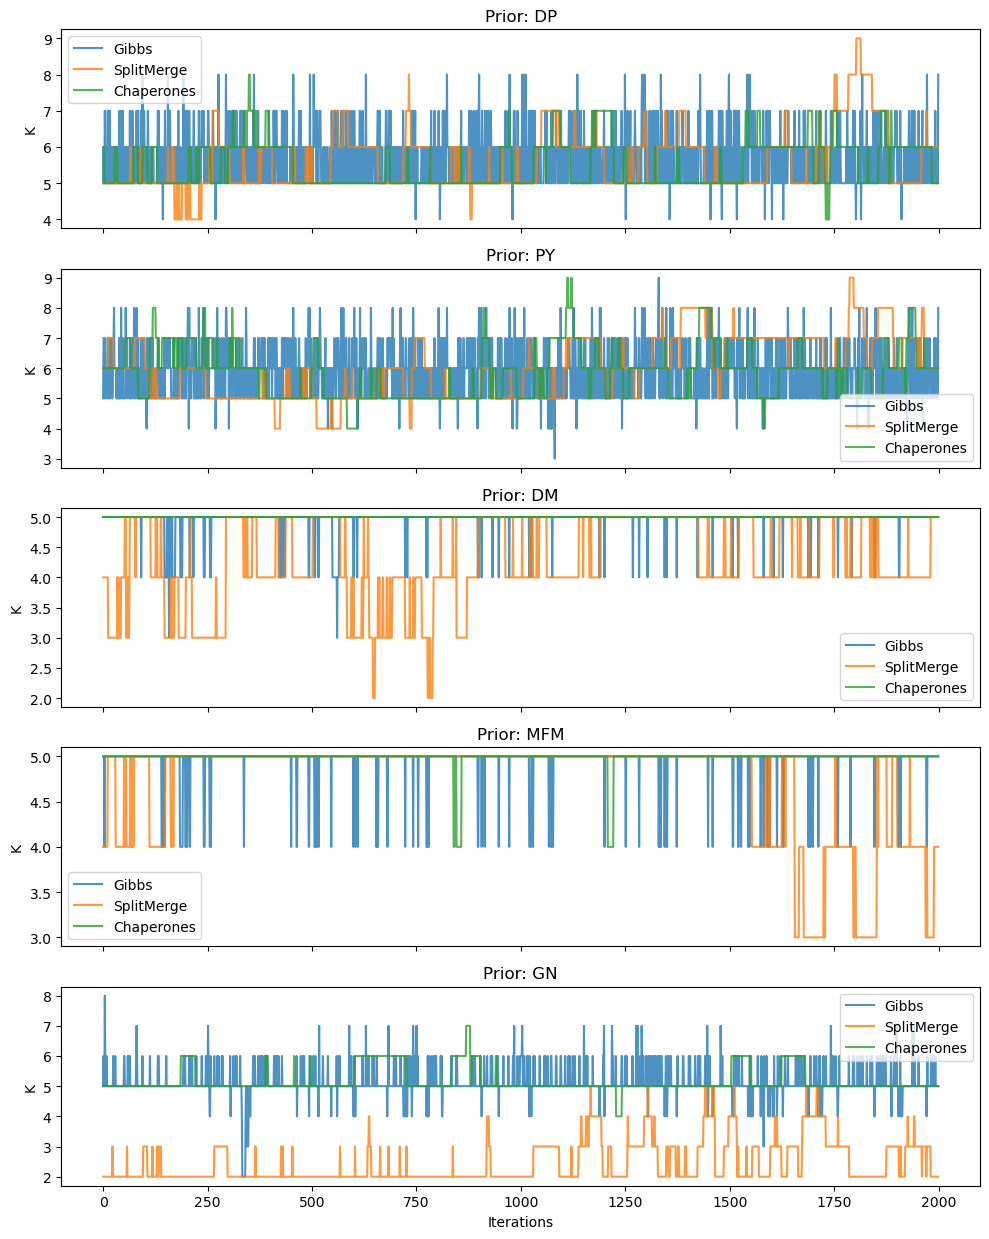

In [24]:
fig, axes = plt.subplots(len(priors), 1, figsize=(10, 2.5 * len(priors)), sharex=True)
for ax, prior_name in zip(axes, priors):
    for sampler_name in sampler_classes:
        samples = inference_results[(prior_name, sampler_name)]["samples"]
        K_trace = [len(np.unique(z)) for z in samples]
        ax.plot(K_trace, label=sampler_name, alpha=0.8)
    ax.set_title(f"Prior: {prior_name}")
    ax.set_ylabel("K")
    ax.legend()
axes[-1].set_xlabel("Iterations")
plt.tight_layout()
plt.show()

### Colombian politics

In [3]:


import pandas as pd
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.cm as cm
import matplotlib.colors as mcolors

path = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\colombianpolitics\poder.xlsx"
df = pd.read_excel(path, sheet_name=1)
print("Dimensions:", df.shape)
columnas_excluir = ["NOMBRE", "EDAD", "GENERO",
    "PARTIDO_POLITICO", "NIVEL_DE_ESTUDIOS", "UNIVERSIDAD",
    "CARRERA", "PREDECESORES", "GOBERNACION",
    "FLAG_MINISTERIO", "FLAG_VIVO"]
columnas_cargos = []
for col in df.columns:
    if col in columnas_excluir:
        continue
    valores = set(df[col].dropna().unique())
    if valores.issubset({0, 1}):
        columnas_cargos.append(col)
B = nx.Graph()
for _, row in df.iterrows():
    nombre = row["NOMBRE"]
    B.add_node(nombre, bipartite="persona", tipo="persona",
        edad=row.get("EDAD"),
        genero=row.get("GENERO"),
        partido=row.get("PARTIDO_POLITICO"),
        nivel_estudios=row.get("NIVEL_DE_ESTUDIOS"),
        universidad=row.get("UNIVERSIDAD"),
        carrera=row.get("CARRERA"),
        predecesores=row.get("PREDECESORES"),
        gobernacion=row.get("GOBERNACION"),
        flag_ministerio=row.get("FLAG_MINISTERIO"),
        flag_vivo=row.get("FLAG_VIVO"))
for cargo in columnas_cargos:
    B.add_node(cargo, bipartite="cargo", tipo="cargo")
for _, row in df.iterrows():
    nombre = row["NOMBRE"]
    for cargo in columnas_cargos:
        if row[cargo] == 1:
            B.add_edge(nombre, cargo, relacion="occupies")
print("Bipartite graph")
print("Nodes:", B.number_of_nodes())
print("Edges:", B.number_of_edges())
personas = {n for n, d in B.nodes(data=True) if d["tipo"] == "persona"}
cargos = {n for n, d in B.nodes(data=True) if d["tipo"] == "cargo"}
print("Number of persons:", len(personas))
print("Number of positions:", len(cargos))
from networkx.algorithms import bipartite
G_personas = bipartite.weighted_projected_graph(B, personas)
print("Projected graph of persons")
print("Nodes:", G_personas.number_of_nodes())
print("Edges:", G_personas.number_of_edges())


Dimensions: (265, 62)
Bipartite graph
Nodes: 314
Edges: 379
Number of persons: 264
Number of positions: 50
Projected graph of persons
Nodes: 264
Edges: 2014


C:\Users\carlo\AppData\Local\Temp\ipykernel_19724\4268285430.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 0.88, 0.96])


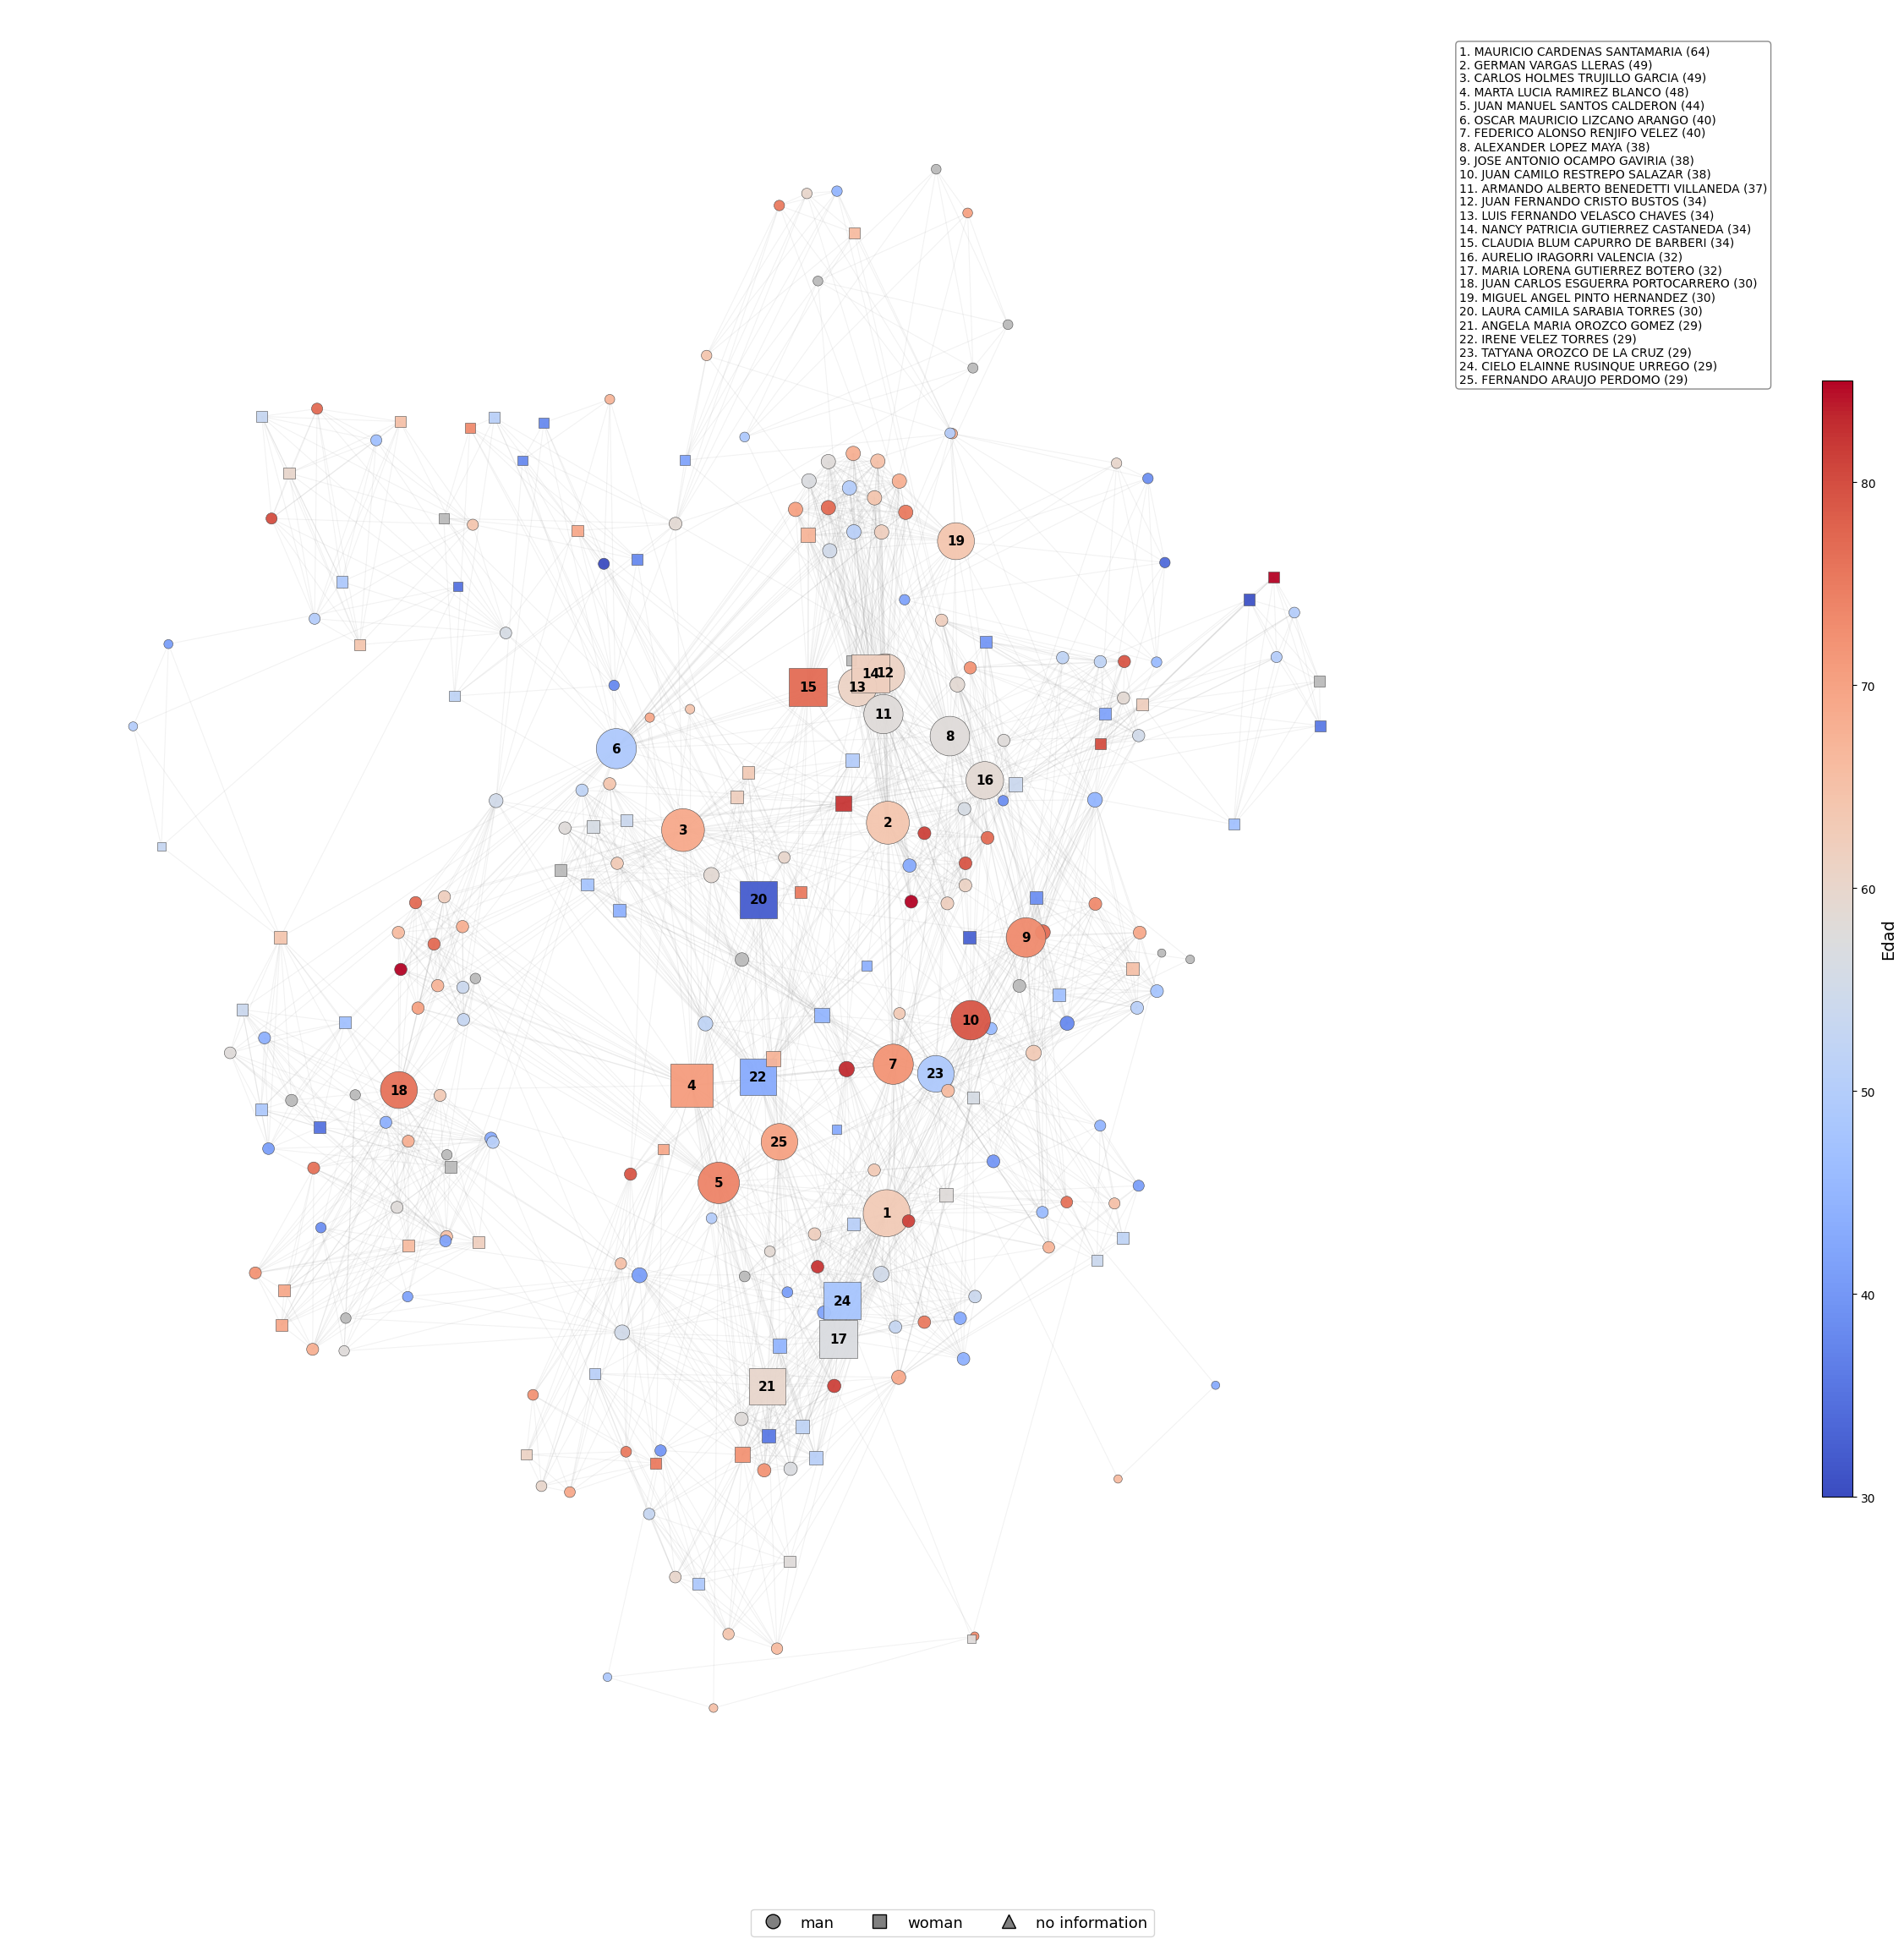

In [4]:

genero_dict = dict(zip(df["NOMBRE"], df["GENERO"]))
edad_dict = dict(zip(df["NOMBRE"], df["EDAD"]))
gob_dict = dict(zip(df["NOMBRE"], df["GOBERNACION"]))
grados = dict(G_personas.degree())
top_n = 25
top_nodes = sorted(grados.items(), key=lambda x: x[1], reverse=True)[:top_n]
top_names = [x[0] for x in top_nodes]
edades_validas = [edad_dict[n] for n in G_personas.nodes() if pd.notna(edad_dict.get(n))]
norm = mcolors.Normalize(vmin=min(edades_validas), vmax=max(edades_validas))
cmap = cm.coolwarm
pos = nx.spring_layout(G_personas, k=2.995, iterations=400, seed=42)
fig, ax = plt.subplots(figsize=(24, 24))
nx.draw_networkx_edges(G_personas, pos, ax=ax, alpha=0.10, width=0.8, edge_color="gray")
hombres = []
mujeres = []
otros = []
for n in G_personas.nodes():
    genero = str(genero_dict.get(n, "")).upper()
    if genero.startswith("M"):
        hombres.append(n)
    elif genero.startswith("F"):
        mujeres.append(n)
    else:
        otros.append(n)
color_map = {}
for n in G_personas.nodes():
    edad = edad_dict.get(n)
    if pd.isna(edad):
        color_map[n] = "#BBBBBB"
    else:
        color_map[n] = cmap(norm(edad))
node_sizes = {}
for n in G_personas.nodes():
    g = grados[n]
    if n in top_names:
        node_sizes[n] = 450 + g * 18
    else:
        node_sizes[n] = 40 + g * 5
nx.draw_networkx_nodes(G_personas, pos, nodelist=hombres, node_shape='o',
    node_size=[node_sizes[n] for n in hombres], node_color=[color_map[n] for n in hombres],
    edgecolors="#444444", linewidths=0.4, alpha=0.95, ax=ax)
nx.draw_networkx_nodes(G_personas, pos, nodelist=mujeres, node_shape='s',
    node_size=[node_sizes[n] for n in mujeres], node_color=[color_map[n] for n in mujeres],
    edgecolors="#444444", linewidths=0.4, alpha=0.95, ax=ax)
nx.draw_networkx_nodes(G_personas, pos, nodelist=otros, node_shape='^', 
    node_size=[node_sizes[n] for n in otros ], node_color=[color_map[n] for n in otros],
    edgecolors="#444444", linewidths=0.4, alpha=0.95, ax=ax)
labels = {}
leyenda_top = []
for idx, (node, grado) in enumerate(top_nodes, start=1):
    labels[node] = str(idx)
    leyenda_top.append(f"{idx}. {node} ({grado})")
nx.draw_networkx_labels(G_personas,pos,labels=labels,font_size=11,font_weight="bold",font_color="black",ax=ax)
texto_leyenda = "\n".join(leyenda_top)
ax.text(1.01, 0.98, texto_leyenda, transform=ax.transAxes, fontsize=10,
    verticalalignment="top", bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.92))
sm = cm.ScalarMappable(cmap=cmap,norm=norm)
sm.set_array([])
cbar_ax = fig.add_axes([0.90, 0.22, 0.015, 0.55])
cbar = fig.colorbar(sm,cax=cbar_ax)
cbar.set_label("Edad",fontsize=14)
legend_elements = [
    Line2D([0], [0],marker='o', color='w', label='man', markerfacecolor='gray', markeredgecolor='black', markersize=12),
    Line2D([0], [0],marker='s',color='w',label='woman',markerfacecolor='gray',markeredgecolor='black',markersize=12),
    Line2D([0], [0],marker='^',color='w',label='no information',markerfacecolor='gray',markeredgecolor='black',markersize=12)
]
fig.legend(handles=legend_elements,loc="lower center",ncol=3,fontsize=13)
ax.axis("off")
plt.tight_layout(rect=[0, 0.03, 0.88, 0.96])
plt.show()

Clustering promedio: 0.8791988846804919
Transitividad global: 0.6593248561913412

Personas con mayor clustering:
                             Persona  Clustering  Grado
263        ANDRES FELIPE ARIAS LEIVA         1.0     14
0           EVERTH BUSTAMANTE GARCIA         1.0     10
262      LENA YANINA ESTRADA ANOKAZI         1.0     14
2          RICARDO JOSE LOZANO PICON         1.0     14
3     JORGE ALBERTO URIBE ECHAVARRIA         1.0     14
4    LUIS EDUARDO MONTEALEGRE LYNETT         1.0     13
5        CAROLINA RENTERIA RODRIGUEZ         1.0     16
245              JULIAN MOLINA GOMEZ         1.0     12
244         JUAN CAMILO DURAN TELLEZ         1.0      2
243        LUIS GUILLERMO PLATA PAEZ         1.0     18
242             NESTOR DIAZ SAAVEDRA         1.0      8
241     JENNIFER KRISTIN ARIAS FALLA         1.0      8
240          JUAN MANUEL CORZO ROMAN         1.0     22
239           TOMAS GONZALEZ ESTRADA         1.0     15
237         GLORIA INES RAMIREZ RIOS         1.

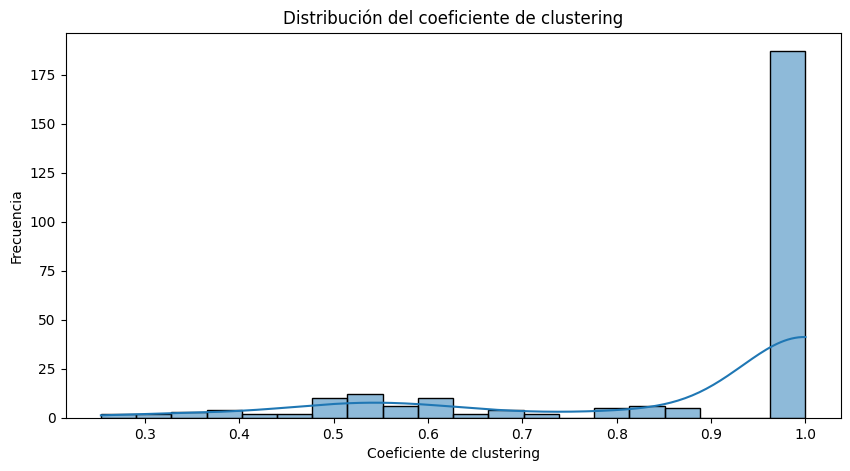

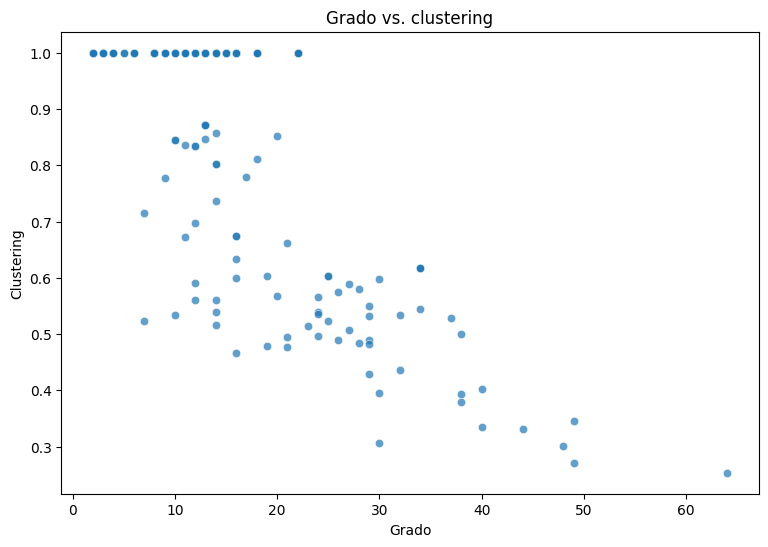

In [6]:
# ==================================================
# 1. MEDIDAS DE CLUSTERING
# ==================================================

# Clustering local de cada nodo
clustering_local = nx.clustering(G_personas)

# Clustering promedio
clustering_promedio = nx.average_clustering(G_personas)

# Transitividad global
transitividad = nx.transitivity(G_personas)

# Distribución del clustering
clustering_df = pd.DataFrame({
    "Persona": list(clustering_local.keys()),
    "Clustering": list(clustering_local.values()),
    "Grado": [G_personas.degree(n) for n in clustering_local]
})

print("Clustering promedio:", clustering_promedio)
print("Transitividad global:", transitividad)

print("\nPersonas con mayor clustering:")
print(
    clustering_df.sort_values(
        "Clustering", ascending=False
    ).head(20)
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    clustering_df["Clustering"],
    bins=20,
    kde=True,
    ax=ax
)

ax.set_title("Distribución del coeficiente de clustering")
ax.set_xlabel("Coeficiente de clustering")
ax.set_ylabel("Frecuencia")

plt.show()


fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=clustering_df,
    x="Grado",
    y="Clustering",
    alpha=0.7,
    ax=ax
)

ax.set_title("Grado vs. clustering")
plt.show()

In [8]:
# ==================================================
# 2. DETECCIÓN DE COMUNIDADES: LOUVAIN
# ==================================================

G_jaccard = bipartite.overlap_weighted_projected_graph(
    B,
    personas,
    jaccard=True
)

comunidades = nx.community.louvain_communities(
    G_jaccard,
    weight="weight",
    resolution=1,
    seed=42
)

# Asignar identificador de comunidad
comunidad_dict = {}

for i, comunidad in enumerate(comunidades):
    for nodo in comunidad:
        comunidad_dict[nodo] = i

# Modularidad
Q = nx.community.modularity(
    G_jaccard,
    comunidades,
    weight="weight"
)

print("Número de comunidades:", len(comunidades))
print("Modularidad:", Q)

print("\nTamaño de las comunidades:")

for i, comunidad in enumerate(comunidades):
    print(f"Comunidad {i}: {len(comunidad)} personas")

Número de comunidades: 14
Modularidad: 0.7842348478440883

Tamaño de las comunidades:
Comunidad 0: 11 personas
Comunidad 1: 40 personas
Comunidad 2: 31 personas
Comunidad 3: 7 personas
Comunidad 4: 12 personas
Comunidad 5: 14 personas
Comunidad 6: 15 personas
Comunidad 7: 16 personas
Comunidad 8: 20 personas
Comunidad 9: 21 personas
Comunidad 10: 16 personas
Comunidad 11: 31 personas
Comunidad 12: 15 personas
Comunidad 13: 15 personas


C:\Users\carlo\AppData\Local\Temp\ipykernel_19724\2501613811.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_com = cm.get_cmap(


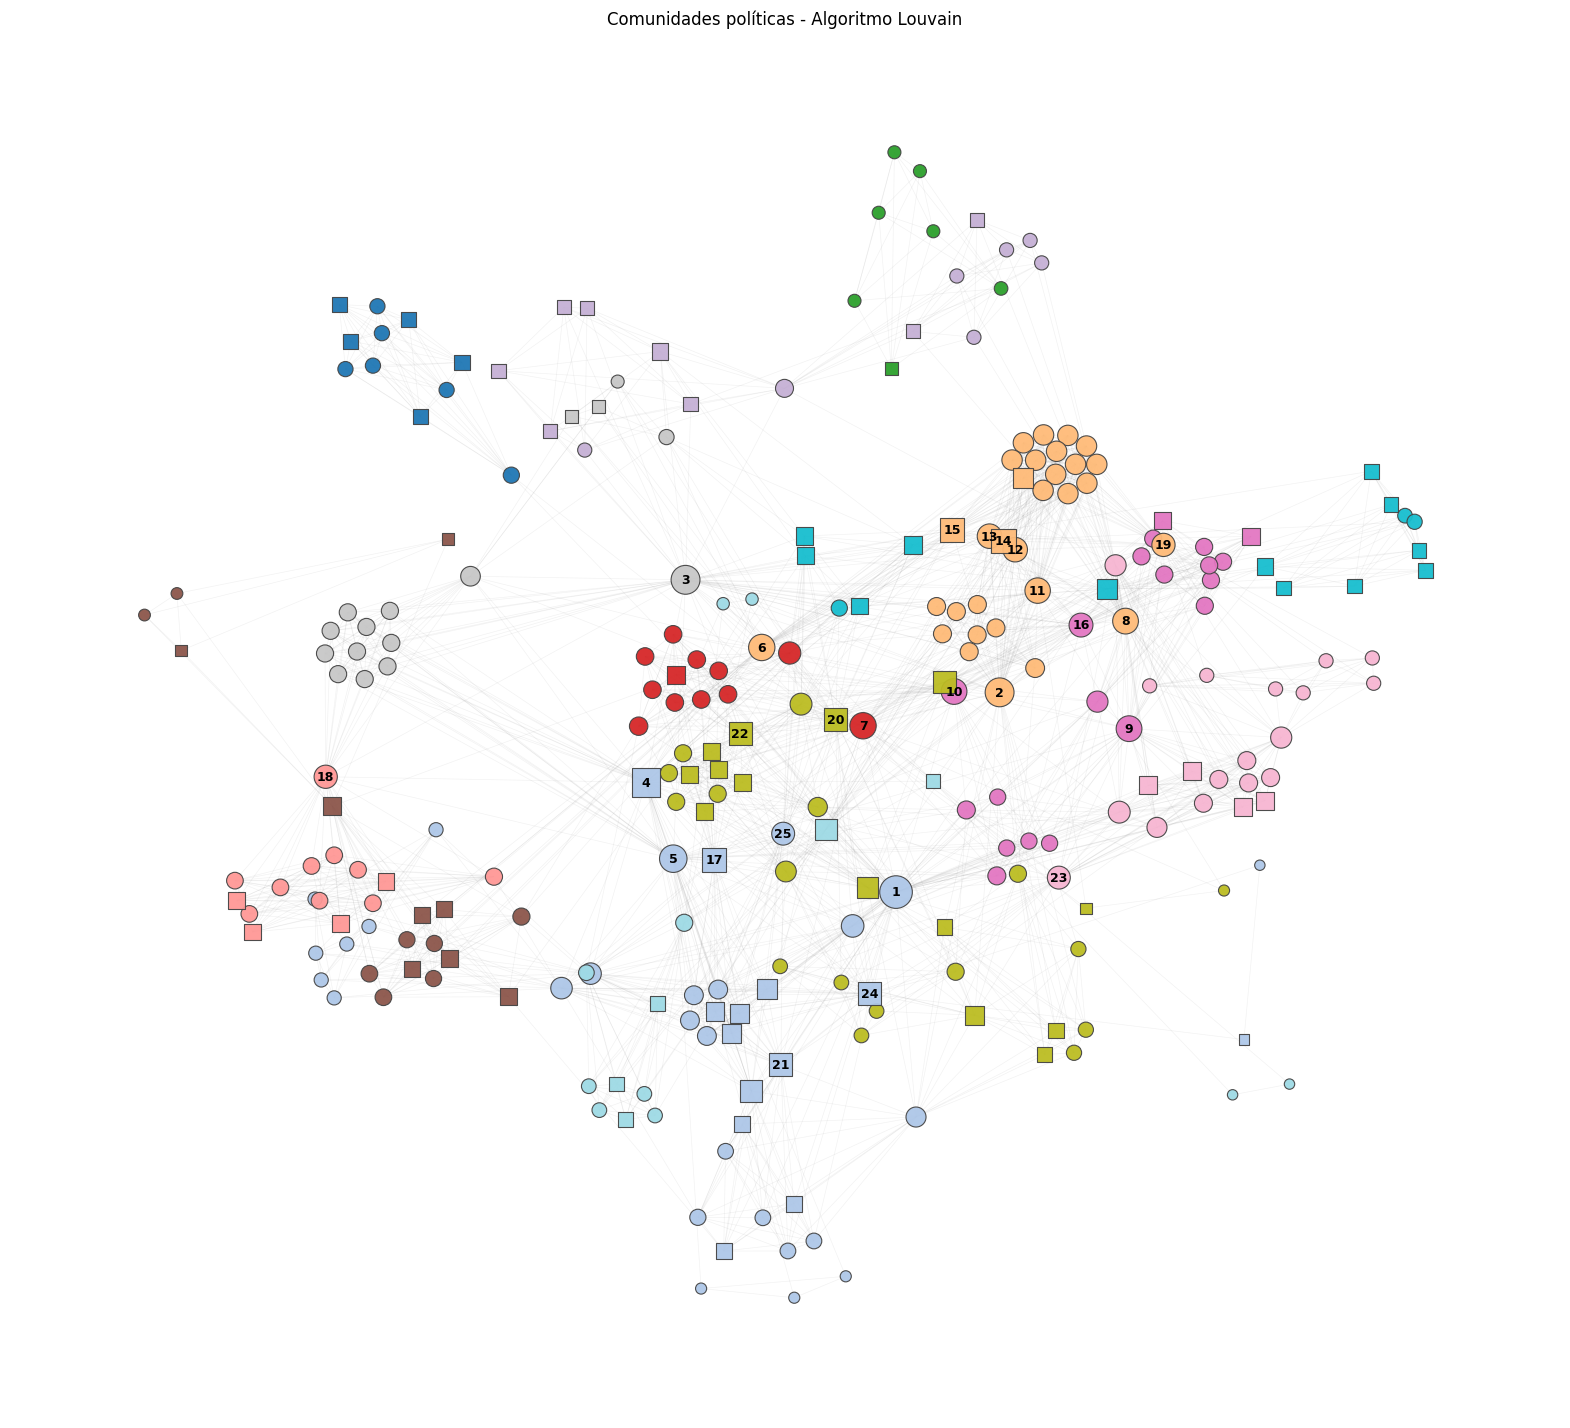

In [11]:
# ==================================================
# 3. VISUALIZACIÓN DE COMUNIDADES
# ==================================================

pos = nx.spring_layout(
    G_jaccard,
    k=1.995,
    iterations=400,
    seed=42,
    weight="weight"
)

fig, ax = plt.subplots(figsize=(20, 18))

# Colores de comunidades
cmap_com = cm.get_cmap(
    "tab20",
    len(comunidades)
)

color_comunidad = {
    nodo: cmap_com(comunidad_dict[nodo])
    for nodo in G_jaccard.nodes()
}

# Aristas
nx.draw_networkx_edges(
    G_jaccard,
    pos,
    alpha=0.10,
    width=0.5,
    edge_color="gray",
    ax=ax
)

# Nodos por género
for genero, shape in [
    ("M", "o"),
    ("F", "s")
]:

    nodos = [
        n for n in G_jaccard.nodes()
        if str(genero_dict.get(n, "")).upper().startswith(genero)
    ]

    nx.draw_networkx_nodes(
        G_jaccard,
        pos,
        nodelist=nodos,
        node_shape=shape,
        node_color=[
            color_comunidad[n] for n in nodos
        ],
        node_size=[
            40 + G_jaccard.degree(n) * 8
            for n in nodos
        ],
        edgecolors="#444444",
        linewidths=0.8,
        alpha=0.95,
        ax=ax
    )

# Personas sin información de género
otros = [
    n for n in G_jaccard.nodes()
    if str(genero_dict.get(n, "")).upper()[:1]
    not in ["M", "F"]
]

nx.draw_networkx_nodes(
    G_jaccard,
    pos,
    nodelist=otros,
    node_shape="^",
    node_color=[
        color_comunidad[n] for n in otros
    ],
    node_size=50,
    ax=ax
)

# Etiquetar las 25 personas con mayor grado
top_nodes = sorted(
    G_jaccard.degree(),
    key=lambda x: x[1],
    reverse=True
)[:25]

labels = {
    n: str(i)
    for i, (n, _) in enumerate(top_nodes, 1)
}

nx.draw_networkx_labels(
    G_jaccard,
    pos,
    labels=labels,
    font_size=9,
    font_weight="bold",
    ax=ax
)

ax.set_title("Comunidades políticas - Algoritmo Louvain")
ax.axis("off")

plt.show()

In [12]:
# ==================================================
# 4. CARACTERIZACIÓN DE COMUNIDADES
# ==================================================

df_comunidades = df.copy()

df_comunidades["COMUNIDAD"] = (
    df_comunidades["NOMBRE"].map(comunidad_dict)
)

# Tamaño de cada comunidad
print(
    df_comunidades.groupby("COMUNIDAD")
    .size()
)

# Edad promedio
print(
    df_comunidades.groupby("COMUNIDAD")["EDAD"]
    .mean()
)

# Distribución por género
print(
    pd.crosstab(
        df_comunidades["COMUNIDAD"],
        df_comunidades["GENERO"],
        normalize="index"
    )
)

# Distribución por partido
print(
    pd.crosstab(
        df_comunidades["COMUNIDAD"],
        df_comunidades["PARTIDO_POLITICO"],
        normalize="index"
    )
)

# Distribución por gobernación
print(
    pd.crosstab(
        df_comunidades["COMUNIDAD"],
        df_comunidades["GOBERNACION"],
        normalize="index"
    )
)

COMUNIDAD
0     11
1     40
2     31
3      7
4     12
5     14
6     16
7     16
8     20
9     21
10    16
11    31
12    15
13    15
dtype: int64
COMUNIDAD
0     60.454545
1     57.485714
2     64.032258
3     59.500000
4     61.833333
5     64.214286
6     57.266667
7     47.428571
8     60.850000
9     49.450000
10    61.000000
11    52.777778
12    57.500000
13    65.200000
Name: EDAD, dtype: float64
GENERO            F         M
COMUNIDAD                    
0          0.454545  0.545455
1          0.325000  0.675000
2          0.096774  0.903226
3          0.142857  0.857143
4          0.083333  0.916667
5          0.285714  0.714286
6          0.500000  0.500000
7          0.500000  0.500000
8          0.100000  0.900000
9          0.190476  0.809524
10         0.125000  0.875000
11         0.451613  0.548387
12         0.800000  0.200000
13         0.333333  0.666667
PARTIDO_POLITICO  ALIANZA VERDE  CAMBIO RADICAL  CENTRO DEMOCRATICO  \
COMUNIDAD                              

In [13]:
resumen = []

for i, comunidad in enumerate(comunidades):

    subgrafo = G_jaccard.subgraph(comunidad)

    resumen.append({
        "Comunidad": i,
        "Personas": len(comunidad),
        "Grado_promedio": sum(
            dict(G_jaccard.degree(comunidad)).values()
        ) / len(comunidad),
        "Clustering_promedio": nx.average_clustering(
            subgrafo,
            weight="weight"
        ),
        "Edad_promedio": df_comunidades[
            df_comunidades["COMUNIDAD"] == i
        ]["EDAD"].mean()
    })

resumen = pd.DataFrame(resumen)

print(resumen)

    Comunidad  Personas  Grado_promedio  Clustering_promedio  Edad_promedio
0           0        11       10.181818             0.899080      60.454545
1           1        40       17.650000             0.505437      57.485714
2           2        31       24.774194             0.581241      64.032258
3           3         7        6.142857             0.841412      59.500000
4           4        12       18.250000             0.575753      61.833333
5           5        14       14.285714             0.817217      64.214286
6           6        15        8.866667             0.638114      57.266667
7           7        16       10.625000             0.581495      47.428571
8           8        20       17.600000             0.524446      60.850000
9           9        21       15.428571             0.710432      49.450000
10         10        16       14.812500             0.664782      61.000000
11         11        31       14.677419             0.540418      52.777778
12         1

In [20]:

# Orden fijo de los nodos para conservar correspondencia con la matriz
nodes = list(G_personas.nodes())

# Matriz de adyacencia ponderada
A_weighted = nx.to_numpy_array(
    G_personas,
    nodelist=nodes,
    weight="weight",
    dtype=float
)

# Matriz binaria
A = (A_weighted > 0).astype(np.int8)

# Matriz no dirigida y simple
A = np.maximum(A, A.T)

# Eliminar posibles auto-relaciones
np.fill_diagonal(A, 0)

# Verificaciones
assert np.all(A == A.T), "La matriz no es simétrica"
assert np.all(np.diag(A) == 0), "La diagonal no es nula"
assert set(np.unique(A)).issubset({0, 1}), "La matriz no es binaria"

n = A.shape[0]
m = int(A.sum() // 2)

print("Número de personas:", n)
print("Número de relaciones:", m)
print("Densidad:", nx.density(G_personas))
print("Matriz:", A.shape)

Número de personas: 264
Número de relaciones: 2014
Densidad: 0.05801359603640972
Matriz: (264, 264)


In [21]:
# Priors de partición

priors = {
    "DM": PartitionPrior(
        kind="DM",
        beta=3.5 / 50,
        H_total=50
    ),

    "DP": PartitionPrior(
        kind="DP",
        alpha=3
    ),

    "PY": PartitionPrior(
        kind="PY",
        alpha=-0.3,
        sigma=0.6
    ),

    "GN": PartitionPrior(
        kind="GN",
        gamma=0.45
    ),

    "PCPP": PartitionPrior(
        kind="PCPP",
        theta=5.0,
        omega=0.5
    )
}


lambda_mfm = 5
eta_mfm = 1

K_values = np.arange(1, n + 1)

from scipy.stats import poisson

p_k = poisson.pmf(K_values, mu=lambda_mfm)

p_k = p_k / p_k.sum()

prior_mfm = PartitionPrior(
    kind="MFM",
    rho=eta_mfm,
    p_k=p_k
)

priors["MFM"] = prior_mfm

In [ ]:
config = SamplerConfig(
    n_iterations=205_000,
    burn_in=5_000,
    thin=100
)

algorithms = {
    #"Gibbs": GibbsSampler, 
    "SplitMerge": SplitMergeSampler, 
    #"Chaperones": ChaperonesSampler, 
    }

def random_initial_partition(n, K_initial=10, seed=42):
    """
    Genera una partición aleatoria inicial con K_initial comunidades.
    """
    if K_initial > n:
        K_initial = n

    rng = np.random.default_rng(seed)

    z = np.zeros(n, dtype=int)

    # Garantizar que todas las comunidades estén representadas
    z[:K_initial] = np.arange(K_initial)

    # Asignación aleatoria de los nodos restantes
    if n > K_initial:
        z[K_initial:] = rng.integers(
            low=0,
            high=K_initial,
            size=n - K_initial
        )

    # Mezclar las asignaciones
    rng.shuffle(z)

    return z

In [23]:
import time

results = {}

for algorithm_name, SamplerClass in algorithms.items():

    for prior_name, prior in priors.items():

        print(
            f"Ejecutando {algorithm_name} "
            f"con prior {prior_name}..."
        )

        # Modelo SBM
        model = SBMModel(
            adjacency=A,
            a=1.0,
            b=1.0
        )

        # Partición inicial
        seed = 42

        z_initial = random_initial_partition(
            n=n,
            K_initial=10,
            seed=seed
        )

        # Sampler
        sampler = SamplerClass(
            model=model,
            prior=prior,
            config=config
        )

        # Tiempo de ejecución
        start_time = time.perf_counter()

        result = sampler.fit(
            initial_partition=z_initial,
            seed=seed
        )

        elapsed = time.perf_counter() - start_time

        # Guardar resultados
        key = f"{algorithm_name}_{prior_name}"

        results[key] = {
            "algorithm": algorithm_name,
            "prior": prior_name,
            "result": result,
            "time_seconds": elapsed,
            "seed": seed,
            "initial_partition": z_initial,
            "config": {
                "n_iterations": config.n_iterations,
                "burn_in": config.burn_in,
                "thin": config.thin
            }
        }

        print(f"Tiempo: {elapsed:.2f} segundos")
        print(f"K final: {len(np.unique(result['final_partition']))}")
        print("-" * 60)

Ejecutando SplitMerge con prior DM...


Sampling: 100%|██████████| 205000/205000 [21:56<00:00, 155.70it/s]


Tiempo: 1316.72 segundos
K final: 8
------------------------------------------------------------
Ejecutando SplitMerge con prior DP...


Sampling: 100%|██████████| 205000/205000 [18:58<00:00, 180.09it/s]


Tiempo: 1138.36 segundos
K final: 14
------------------------------------------------------------
Ejecutando SplitMerge con prior PY...


Sampling: 100%|██████████| 205000/205000 [19:50<00:00, 172.14it/s]


... (3 outputs left out)

Sampling: 100%|██████████| 205000/205000 [27:35<00:00, 123.80it/s]


Tiempo: 1655.97 segundos
K final: 12
------------------------------------------------------------
Ejecutando SplitMerge con prior MFM...


Sampling: 100%|██████████| 205000/205000 [22:04<00:00, 154.73it/s]

Tiempo: 1324.96 segundos
K final: 14
------------------------------------------------------------


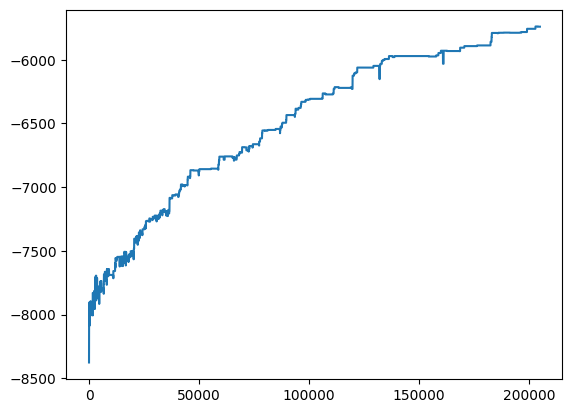

In [26]:
plt.plot(results['SplitMerge_DP']['result']['log_posterior'])

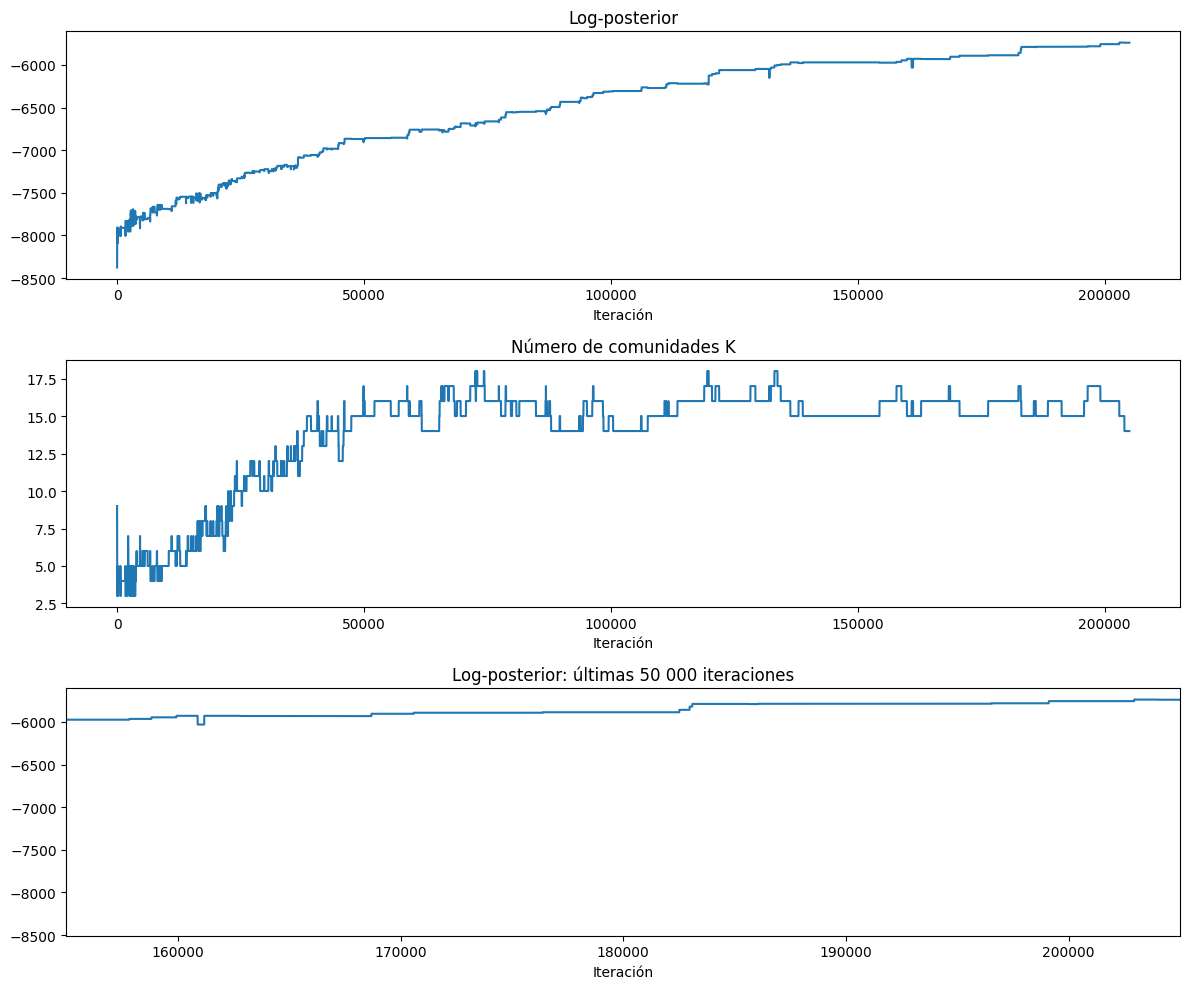

In [39]:
import matplotlib.pyplot as plt

result = results["SplitMerge_DP"]['result']

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(result['log_posterior'])
axes[0].set_title("Log-posterior")
axes[0].set_xlabel("Iteración")

axes[1].plot(result['n_communities'])
axes[1].set_title("Número de comunidades K")
axes[1].set_xlabel("Iteración")

axes[2].plot(result['log_posterior'])
axes[2].set_title("Log-posterior: últimas 50 000 iteraciones")
axes[2].set_xlabel("Iteración")
axes[2].set_xlim(max(0, len(result['log_posterior']) - 50000),
                 len(result['log_posterior']))

plt.tight_layout()
plt.show()

In [25]:
import pickle
from pathlib import Path

output_dir = Path(r"C:\Users\carlo\OneDrive\Documents\blockdynamicsnetwork\data\colombianpolitics")

output_dir.mkdir(parents=True, exist_ok=True)

pickle_path = output_dir / "sbm_colombian_politics.pkl"

data_to_save = {
    "adjacency_matrix": A,
    "nodes": nodes,
    "n_nodes": n,
    "n_edges": m,
    "results": results,
    "priors": priors,
    "algorithms": list(algorithms.keys()),
    "config": {
        "n_iterations": config.n_iterations,
        "burn_in": config.burn_in,
        "thin": config.thin
    }
}

with open(pickle_path, "wb") as f:
    pickle.dump(data_to_save, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Resultados guardados en: {pickle_path}")

Resultados guardados en: C:\Users\carlo\OneDrive\Documents\blockdynamicsnetwork\data\colombianpolitics\sbm_colombian_politics.pkl
